# Why This Action? — 02 · Experimentos

Segunda parte del MVP. El cuaderno 01 mostró que las piezas encajan con **un** paciente y **una** semilla. Este cuaderno responde lo que un revisor preguntaría después:

| § | Pregunta | Qué se añade |
|---|---|---|
| 1 | ¿Se sostiene con otros datos y otros pacientes? | 8 conjuntos de datos × 3 pacientes, con el **éxito real** en el mundo verdadero |
| 1 | ¿Hay alguna garantía que no dependa del bootstrap? | **Caja de confianza simultánea** para grafo y mecanismos (caso lineal) |
| 2 | ¿La ventaja en consultas es real o el rival era débil? | Dos líneas de base: búsqueda al azar y BO clásica sobre el plan |
| 3 | ¿De qué caminos depende el plan? (Q5) | Reparto de Shapley entre mecanismos y bloqueo |
| 4 | ¿Cómo crece el riesgo con el largo del camino? | Cota por suma, comprobada en simulación |
| 5 | ¿Se puede elegir un plan "más típico" con un grado de evidencia claro? | Selección por **valor p conformal** con una medida causal |

Usa `wta_core.py`, que es el mismo código del cuaderno 01 empaquetado como funciones. Todo sigue siendo el ejemplo sintético lineal: **las cifras son de simulación, no de datos reales**.

## 0 · Preparación

Carga el núcleo y la caja negra. `pick_patients` elige pacientes "no aptos" cuyo margen permite que exista algún plan dentro de los límites de acción.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time, itertools
from math import factorial
from scipy.stats import norm
from wta_core import *
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

prob = Problem()                                          # la caja negra del hospital (misma del cuaderno 01)
def pick_patients(n, rng):
    """Pacientes 'no aptos' para los que existe algún plan dentro de los límites de acción."""
    pool = sample_world(40 * n, rng); m = prob.blackbox().margin(pool)
    return pool[(m < -1.0) & (m > -2.2)][:n]
print("Margen del paciente del ejemplo:", round(float(prob.blackbox().margin(X0)[0]), 3))

Margen del paciente del ejemplo: -1.862


## 1 · Variabilidad, éxito real y una garantía formal

**Qué hace.** Para 8 conjuntos de datos distintos y 3 pacientes en cada uno compara tres formas de recomendar:

1. **Ingenuo:** el plan más barato según una sola estimación del modelo causal.
2. **Robusto por bootstrap:** nuestro plan con riesgo 10 % sobre versiones bootstrap (grafo + mecanismos).
3. **Robusto por caja de confianza:** el plan debe funcionar en **todos** los vértices de una caja de intervalos de confianza simultáneos al 90 %.

Para cada plan mide el **éxito real**: si funciona en el modelo causal verdadero. Eso solo se puede medir porque el ejemplo es sintético.

**Por qué la caja.** El cuaderno 01 mostró que la probabilidad de éxito por bootstrap está calibrada *en promedio* sobre conjuntos de datos, pero no para un conjunto de datos concreto. Es la misma distinción que en conformal prediction entre garantía marginal y condicional. La caja da una afirmación distinta y más fuerte: con probabilidad ≥ 90 % sobre los datos, el modelo verdadero está dentro, y entonces el plan funciona.

**Supuestos de la garantía de la caja:** mecanismos lineales, orden causal conocido, y que el peor caso del margen esté en un vértice (cierto si el margen es monótono en cada peso). Cubre las capas 1 y 2 a la vez, porque una flecha ausente es un peso igual a cero dentro de la caja.

**Literatura**
- *Confidence Sets for Causal Orderings* (Wang, Kolar, Drton, 2023), para quitar el supuesto de orden conocido. *Pendiente de leer.*
- *Your Assumed DAG is Wrong and Here's How To Deal With It* (Padh y otros, 2025): cotas sobre una colección de grafos. *Solo resumen.*
- *On the Adversarial Robustness of Causal Algorithmic Recourse* (ICML 2022): **§4**, mismo espíritu de peor caso sobre un conjunto de incertidumbre, pero en los datos del paciente.
- NeurIPS 2020: **§3**, sin el modelo verdadero no hay garantía.

**Gap declarado.** ICML 2022 deja la incertidumbre del modelo causal fuera (Apéndice A). NeurIPS 2020 la modela sin garantía de cobertura.

**Qué mirar.** La columna ÉXITO REAL, y cuánto más cuesta la caja frente al bootstrap.

In [2]:
def naive_plan(x, X_obs, graphs, bb):
    """El plan más barato según UNA estimación del modelo causal (malla gruesa con la caja negra real)."""
    Wp = make_worlds(fit_mechanisms(X_obs, graphs[0][0]))
    hs, bs = np.linspace(*H_RANGE, 61), np.linspace(*B_RANGE, 41)
    G = np.array([(h, b, k) for k in (0, 1) for h in hs for b in bs])
    m = bb.margin(counterfactual(x, Wp, G)[:, 0, :]); ok = m >= 0
    return G[ok][np.argmin(plan_cost(G[ok]))] if ok.any() else None

def true_success(x, plan):
    return float(prob.blackbox().margin(counterfactual(x, TRUE_WORLD, plan[None])[0])[0] >= 0)

ALPHA = 0.10; rows = []; t0 = time.time()
for d in range(8):                                        # 8 conjuntos de datos distintos
    rng = np.random.default_rng(100 + d)
    X_obs = sample_world(300, rng); graphs = bootstrap_graphs(X_obs, B=200, rng=rng)
    W_boot = sample_worlds(X_obs, graphs, 100, rng); W_new = sample_worlds(X_obs, graphs, 300, rng)
    W_box, _ = confidence_box_worlds(X_obs, ALPHA)
    for x in pick_patients(3, rng):                       # 3 pacientes por conjunto de datos
        res = {}
        bb = prob.blackbox(); res["ingenuo"] = (naive_plan(x, X_obs, graphs, bb), bb.n)
        bb = prob.blackbox(); pl, inf = solve_bo(prob, x, W_boot, ALPHA, bb, n_iter=30, n_cand=800, seed=d); res["bootstrap"] = (pl, bb.n)
        bb = prob.blackbox(); pl, inf = solve_bo(prob, x, W_box, 0.0, bb, n_iter=30, n_cand=800, seed=d);  res["caja"] = (pl, bb.n)
        for nm, (pl, q) in res.items():
            if pl is None: rows.append((d, nm, np.nan, np.nan, np.nan, q)); continue
            p_new = success_prob(prob.blackbox().margin(counterfactual(x, W_new, pl[None])[0]))[0]
            rows.append((d, nm, plan_cost(pl[None])[0], p_new, true_success(x, pl), q))
print(f"{len(rows) // 3} casos (8 conjuntos de datos x 3 pacientes) en {time.time() - t0:.0f} s\n")
print(f"{'método':<26}{'con plan':>9}{'costo medio':>13}{'éxito estimado':>16}{'ÉXITO REAL':>12}{'consultas':>11}")
for nm, lab in [("ingenuo", "ingenuo (1 estimación)"), ("bootstrap", "robusto bootstrap 90 %"), ("caja", "robusto caja 90 %")]:
    R = np.array([r[2:] for r in rows if r[1] == nm], float); ok = ~np.isnan(R[:, 0])
    print(f"{lab:<26}{ok.sum():>6}/{len(R)}{R[ok, 0].mean():>10.3f} ± {R[ok, 0].std():.2f}{R[ok, 1].mean():>12.2f}{R[ok, 2].mean():>12.2f}{np.median(R[:, 3]):>11.0f}")
print("\nÉxito real por conjunto de datos (fracción de pacientes cuyo plan funciona en el mundo verdadero):")
for nm in ["ingenuo", "bootstrap", "caja"]:
    by = [np.nanmean([r[4] for r in rows if r[1] == nm and r[0] == d]) for d in range(8)]
    print(f"  {nm:<10}", " ".join(f"{v:.2f}" for v in by))

24 casos (8 conjuntos de datos x 3 pacientes) en 155 s

método                     con plan  costo medio  éxito estimado  ÉXITO REAL  consultas
ingenuo (1 estimación)        24/24     1.028 ± 0.31        0.71        0.79       5002
robusto bootstrap 90 %        24/24     1.036 ± 0.32        0.97        1.00        139
robusto caja 90 %             24/24     1.111 ± 0.40        1.00        1.00        103

Éxito real por conjunto de datos (fracción de pacientes cuyo plan funciona en el mundo verdadero):
  ingenuo    0.67 0.33 0.67 1.00 1.00 0.67 1.00 1.00
  bootstrap  1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00
  caja       1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00


## 2 · ¿La ventaja en consultas es real?

**Qué hace.** Compara tres buscadores sobre el **mismo** problema robusto (100 versiones, riesgo 10 %):

- **Búsqueda al azar:** prueba planes al azar; cada uno cuesta 100 consultas (la caja negra en todas las versiones).
- **BO clásica sobre el plan:** un sustituto modela el margen robusto como función del plan. No usa la estructura, así que cada evaluación también cuesta 100 consultas.
- **La nuestra (compuesta):** el sustituto modela la caja negra; cada paso cuesta 1 consulta, más la certificación.

El objetivo es llegar a un plan certificado a menos de 3 % del óptimo de referencia, que se calcula con una malla densa solo para medir.

**Literatura**
- *Bayesian Optimization of Composite Functions* (Astudillo y Frazier, ICML 2019).
- *Bayesian Optimization with Unknown Constraints* (Gelbart y otros, 2014): es la línea de base "BO sobre el plan".
- Survey de recourse: **§4.1.4**, acceso limitado por consultas.

**Gap declarado.** NeurIPS 2020 (§6): gradiente o fuerza bruta. Esta comparación todavía **no** es contra su método; eso va en el cuaderno 03.

**Qué mirar.** Las consultas de cada método y también los casos donde el nuestro queda lejos del óptimo: hay que reportarlos.

In [3]:
rng = np.random.default_rng(11)
X_obs = sample_world(300, rng); graphs = bootstrap_graphs(X_obs, B=300, rng=rng)
WORLDS = sample_worlds(X_obs, graphs, 100, rng); EPS = 0.10; nW = 100

def full_eval(x, plans, bb):
    """Evaluación completa de un plan: la caja negra en TODAS las versiones (nW consultas por plan)."""
    M = bb.margin(counterfactual(x, WORLDS, plans).reshape(-1, 5)).reshape(len(plans), nW)
    return robust_margin(M, EPS)[0]

def reference_cost(x):
    """El óptimo de referencia: malla densa con la caja negra real (solo para medir, no cuenta)."""
    hs, bs = np.linspace(*H_RANGE, 121), np.linspace(*B_RANGE, 81)
    G = np.array([(h, b, k) for k in (0, 1) for h in hs for b in bs])
    r = np.concatenate([full_eval(x, G[i:i + 2000], prob.blackbox()) for i in range(0, len(G), 2000)])
    return plan_cost(G[r >= 0]).min()

def random_search(x, n_eval, rng):
    bb = prob.blackbox(); P = sample_plans(n_eval, rng); r = full_eval(x, P, bb); c = plan_cost(P)
    best = np.minimum.accumulate(np.where(r >= 0, c, np.inf))
    return (np.arange(1, n_eval + 1) * nW), best

def plan_space_bo(x, n_eval, rng):
    """BO clásica: el sustituto modela el margen robusto como función DEL PLAN (no usa la estructura).
    Cada evaluación cuesta nW consultas porque necesita la caja negra en todas las versiones."""
    bb = prob.blackbox(); P = sample_plans(6, rng); r = full_eval(x, P, bb)
    cand = sample_plans(3000, rng); cc = plan_cost(cand); hist = []
    for it in range(n_eval - 6):
        gp = make_gp().fit(P, r); mu, sd = gp.predict(cand, return_std=True); pf = norm.cdf(mu / np.maximum(sd, 1e-6))
        feas = r >= 0; c_star = plan_cost(P[feas]).min() if feas.any() else np.inf
        acq = pf if not np.isfinite(c_star) else np.maximum(c_star - cc, 0) * pf
        if acq.max() <= 1e-9: acq = pf * (1 - pf)
        i = int(np.argmax(acq)); P = np.vstack([P, cand[i]]); r = np.append(r, full_eval(x, cand[i][None], bb))
    best = np.minimum.accumulate(np.where(r >= 0, plan_cost(P), np.inf))
    return (np.arange(1, len(P) + 1) * nW), best

def queries_to(q, best, target):
    hit = np.flatnonzero(best <= target); return q[hit[0]] if len(hit) else np.inf

rows = []; t0 = time.time()
for i, x in enumerate(pick_patients(5, rng)):
    ref = reference_cost(x); tol = 1.03 * ref           # objetivo: quedar a 3 % del óptimo de referencia
    bb = prob.blackbox(); pl, inf = solve_bo(prob, x, WORLDS, EPS, bb, seed=i)
    ours_c = plan_cost(pl[None])[0] if pl is not None else np.inf
    q_r, b_r = random_search(x, 150, rng); q_p, b_p = plan_space_bo(x, 60, rng)
    rows.append((ref, ours_c, bb.n, queries_to(q_r, b_r, tol), b_r[-1], queries_to(q_p, b_p, tol), b_p[-1]))
print(f"5 pacientes en {time.time() - t0:.0f} s. Objetivo: un plan certificado a 3 % del óptimo de referencia.\n")
print("paciente | óptimo ref. | NUESTRO: costo, consultas | búsqueda al azar: consultas (costo final) | BO sobre el plan: consultas (costo final)")
for i, r in enumerate(rows):
    f = lambda q: "no llega" if not np.isfinite(q) else f"{q:,.0f}"
    print(f"   {i + 1}     |    {r[0]:.3f}    |     {r[1]:.3f},  {r[2]:>4}          |        {f(r[3]):>9} ({r[4]:.3f})              |      {f(r[5]):>9} ({r[6]:.3f})")
R = np.array(rows)
print(f"\nBrecha media de nuestro plan frente al óptimo de referencia: {100 * np.mean(R[:, 1] / R[:, 0] - 1):+.1f} %")
print(f"Consultas medianas: nuestro {np.median(R[:, 2]):.0f} | al azar (15,000 máx.) {np.median(R[:, 3]):,.0f} | BO sobre el plan (6,000 máx.) {np.median(R[:, 5]):,.0f}")

5 pacientes en 46 s. Objetivo: un plan certificado a 3 % del óptimo de referencia.

paciente | óptimo ref. | NUESTRO: costo, consultas | búsqueda al azar: consultas (costo final) | BO sobre el plan: consultas (costo final)
   1     |    1.162    |     1.156,   149          |         no llega (1.276)              |          1,400 (1.166)
   2     |    0.888    |     0.889,   149          |         no llega (0.998)              |            800 (0.902)
   3     |    1.325    |     1.324,   149          |         no llega (1.366)              |          1,100 (1.344)
   4     |    1.300    |     1.299,   149          |           12,000 (1.331)              |            800 (1.294)
   5     |    1.312    |     1.438,   149          |         no llega (1.375)              |          1,100 (1.309)

Brecha media de nuestro plan frente al óptimo de referencia: +1.8 %
Consultas medianas: nuestro 149 | al azar (15,000 máx.) inf | BO sobre el plan (6,000 máx.) 1,100


## 3 · Q5: ¿de qué depende el plan?

**Qué hace.** Reparte el margen que gana el plan entre sus piezas con valores de Shapley: los efectos directos de los cambios, cada mecanismo por el que viaja el efecto y el bloqueo.

**Literatura**
- Posición 2026 (Karimi): **Apéndice C, RQ6–RQ7**, qué consultas causales sirven a cada usuario.
- *Shapley Flow* (Wang, Wiens y Lundberg, AISTATS 2021): atribución por caminos de un grafo causal. *Pendiente de leer.*

**Gap declarado.** NeurIPS 2020 entrega el plan sin decir de qué mecanismos depende su validez.

**Cómo leer el código.** `value(T)` es el margen mediano del plan cuando solo operan las piezas de T. Con tres jugadores el valor de Shapley se calcula exacto. La comprobación final verifica que las contribuciones suman el margen final.

**Qué mirar.** Qué piezas aportan más que la holgura del plan: si fallan, el plan deja de ser válido.

In [4]:
rng = np.random.default_rng(21)
bb = prob.blackbox(); plan, info = solve_bo(prob, X0, WORLDS, EPS, bb, seed=0)
print("Plan:", fmt(plan), "| costo", round(plan_cost(plan[None])[0], 3))

PLAYERS = [("HbA1c", "eGFR"), ("eGFR", "Hb"), "bloqueo"]
bba = prob.blackbox()
def value(T):
    """Margen mediano del plan cuando SOLO operan las piezas de T (las demás flechas no transmiten;
    sin 'bloqueo' en T, el bloqueo no funciona)."""
    failed = [e for e in PLAYERS[:2] if e not in T]
    p = plan.copy(); p[2] = plan[2] if "bloqueo" in T else 0
    return float(np.median(bba.margin(counterfactual(X0, WORLDS, p[None], failed)[0])))

n = len(PLAYERS); phi = {}
for pl_ in PLAYERS:
    others = [q for q in PLAYERS if q != pl_]; s = 0.0
    for r in range(n):
        for T in itertools.combinations(others, r):
            s += factorial(r) * factorial(n - r - 1) / factorial(n) * (value(set(T) | {pl_}) - value(set(T)))
    phi[pl_] = s
m_fact = float(bba.margin(X0)[0]); v0 = value(set()); vN = value(set(PLAYERS))
print(f"\nQ5 · ¿De qué depende el plan?  (margen del paciente hoy: {m_fact:+.3f})")
print(f"  efectos directos de los cambios (sin ninguna flecha ni bloqueo): {v0 - m_fact:+.3f}")
for pl_ in PLAYERS:
    nm = pl_ if isinstance(pl_, str) else f"{pl_[0]} -> {pl_[1]}"
    print(f"  {nm:<16} {phi[pl_]:+.3f}")
print(f"  suma = margen final {vN:+.3f}   (comprobación: {m_fact + (v0 - m_fact) + sum(phi.values()):+.3f})")
slack = vN
print(f"\nHolgura del plan: {slack:+.3f}. Piezas cuya contribución supera la holgura (si fallan, el plan cae): "
      + ", ".join((p if isinstance(p, str) else f'{p[0]}->{p[1]}') for p in PLAYERS if phi[p] > slack))

Plan: HbA1c -0.17, Hb +2.00, bloqueo=sí | costo 1.17

Q5 · ¿De qué depende el plan?  (margen del paciente hoy: -1.862)
  efectos directos de los cambios (sin ninguna flecha ni bloqueo): +0.584
  HbA1c -> eGFR    +0.016
  eGFR -> Hb       +0.022
  bloqueo          +1.257
  suma = margen final +0.017   (comprobación: +0.017)

Holgura del plan: +0.017. Piezas cuya contribución supera la holgura (si fallan, el plan cae): eGFR->Hb, bloqueo


## 4 · El riesgo crece con el largo del camino

**Qué hace.** Comprueba en simulación la cota que nos faltaba. En una cadena de L flechas se pone un intervalo conformal con error α a cada mecanismo y se mide con qué frecuencia aciertan **todos** a la vez.

**La proposición.** Si cada intervalo falla con probabilidad a lo sumo α, la probabilidad de que falle alguno de los L es a lo sumo L·α (cota de unión). No requiere independencia. Si los errores fueran independientes, la cobertura conjunta sería (1 − α)^L.

**Literatura**
- *A Gentle Introduction to Conformal Prediction* (Angelopoulos y Bates): **§1.1**.
- Posición 2026: **RQ4**, cotas de cómo los errores del modelo causal afectan la explicación.

**Gap declarado.** La RQ4 pide estas cotas y no las da.

**Advertencia.** La simulación es **observacional**: los casos de prueba vienen de la misma distribución que la calibración. Para un plan, intervenir cambia la distribución de los padres y hace falta la versión ponderada o localizada. Eso sigue pendiente.

**Qué mirar.** Que la cobertura medida queda por encima de la cota y cerca de (1 − α)^L.

largo del camino | cobertura conjunta medida | cota por suma (1 - L·alfa) | si fueran independientes (1 - alfa)^L
       1         |          0.953            |          0.950           |        0.950
       2         |          0.904            |          0.900           |        0.902
       3         |          0.857            |          0.850           |        0.857
       4         |          0.815            |          0.800           |        0.815
       5         |          0.775            |          0.750           |        0.774
       6         |          0.737            |          0.700           |        0.735
       7         |          0.703            |          0.650           |        0.698
       8         |          0.665            |          0.600           |        0.663


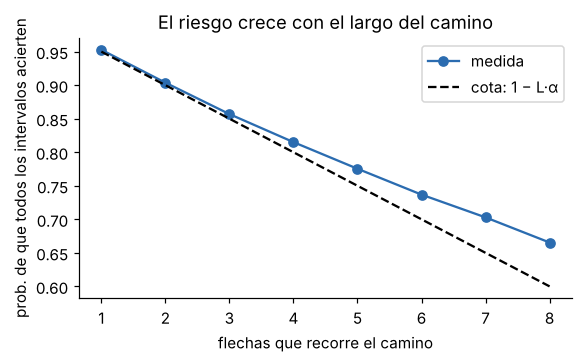

In [5]:
def chain_coverage(L, alpha, rng, n_fit=300, n_cal=300, n_test=4000):
    """Cadena X0 -> X1 -> ... -> XL. Un intervalo conformal por flecha con error alpha.
    Devuelve la fracción de casos nuevos en que TODOS los intervalos del camino aciertan."""
    w = rng.uniform(0.5, 1.5, L) * rng.choice([-1, 1], L)
    def sim(n):
        X = np.zeros((n, L + 1)); X[:, 0] = rng.standard_normal(n)
        for j in range(1, L + 1): X[:, j] = w[j - 1] * X[:, j - 1] + rng.standard_normal(n)
        return X
    A, B, T = sim(n_fit), sim(n_cal), sim(n_test); ok = np.ones(n_test, bool)
    for j in range(1, L + 1):
        b = np.polyfit(A[:, j - 1], A[:, j], 1)
        s = np.abs(B[:, j] - np.polyval(b, B[:, j - 1]))
        q = np.quantile(s, min(1, np.ceil((n_cal + 1) * (1 - alpha)) / n_cal))
        ok &= np.abs(T[:, j] - np.polyval(b, T[:, j - 1])) <= q
    return ok.mean()

rng = np.random.default_rng(31); alpha = 0.05; Ls = range(1, 9)
cov = [np.mean([chain_coverage(L, alpha, rng) for _ in range(60)]) for L in Ls]
print("largo del camino | cobertura conjunta medida | cota por suma (1 - L·alfa) | si fueran independientes (1 - alfa)^L")
for L, c in zip(Ls, cov): print(f"       {L}         |          {c:.3f}            |          {1 - L * alpha:.3f}           |        {(1 - alpha) ** L:.3f}")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.plot(list(Ls), cov, "o-", color="#2B6CB0", label="medida"); ax.plot(list(Ls), [1 - L * alpha for L in Ls], "k--", label="cota: 1 − L·α")
ax.set(xlabel="flechas que recorre el camino", ylabel="prob. de que todos los intervalos acierten", title="El riesgo crece con el largo del camino"); ax.legend(); plt.tight_layout(); plt.show()

## 5 · Selección por valor p conformal con una medida causal

**Qué hace.** Lleva la idea de Johansson y otros a nuestro marco. En vez de quedarse con el plan más barato, toma todos los planes **certificados** que cuestan hasta 25 % más y, para cada uno, calcula un valor p conformal de la afirmación "después del plan, este paciente se parece a las personas aptas". Un valor p alto significa que el resultado del plan es típico; uno bajo, que es un caso raro.

**La medida causal.** Johansson mide la tipicidad en el espacio de rasgos o de SHAP y pide, como trabajo futuro, medidas causales. Aquí cada persona se representa por los **residuos estandarizados de cada mecanismo**: cuánto se aparta cada variable de lo que el modelo causal predice a partir de sus padres. Un plan que empuja mucho una variable, o que bloquea una flecha, deja residuos grandes.

**Literatura**
- *Conformal Selection of Counterfactual Explanations* (Johansson y otros, 2026): **§2.4**, **§3.1** y trabajo futuro.
- *Testing for Outliers with Conformal p-values* (Bates y otros, 2021). *Pendiente de leer.*
- *CONFEX* (2025): **§4.1**.
- *On Data Manifolds Entailed by Structural Causal Models* (ICML 2023): distancia causalmente informada.

**Gap declarado.** Johansson y otros: su medida "refleja el comportamiento del modelo y no los mecanismos causales", y proponen investigar "nociones causales de plausibilidad" y combinarlas con restricciones de accionabilidad.

**Advertencia.** El valor p es válido si el caso evaluado es intercambiable con la calibración. Un paciente después de un plan elegido por un optimizador no lo es, así que aquí el valor p se usa como **puntaje para ordenar planes**, no como garantía.

**Qué mirar.** Cuánto sube el valor p y cuánto cuesta, entre el plan de costo mínimo y el más conforme.

62 planes certificados entre el costo mínimo y +25 %.

paciente hoy            : valor p causal 0.155 | valor p en rasgos 0.067
plan de costo mínimo    : costo 1.169 | valor p causal 0.145 | valor p en rasgos 0.120 | HbA1c -0.17, Hb +2.00, bloqueo=sí
más conforme (causal)   : costo 1.419 | valor p causal 0.815 | valor p en rasgos 0.858 | HbA1c -1.04, Hb +0.76, bloqueo=sí
más conforme (rasgos)   : costo 1.419 | valor p causal 0.815 | valor p en rasgos 0.858 | HbA1c -1.04, Hb +0.76, bloqueo=sí


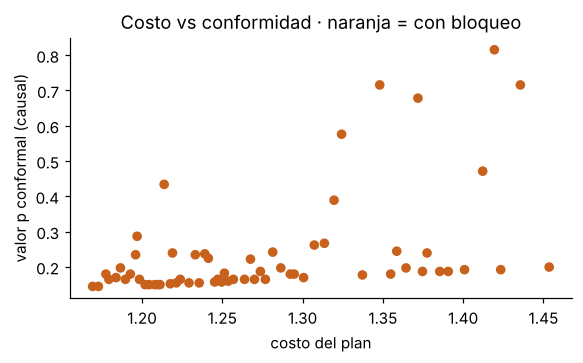

In [6]:
# --- Representación causal: residuos estandarizados de cada mecanismo (qué tan "típico" es el caso para el modelo causal)
g_top = graphs[0][0]; W_hat = fit_mechanisms(X_obs, g_top)
b_hat = X_obs.mean(0) - X_obs.mean(0) @ W_hat.T
sd_hat = (X_obs - (b_hat + X_obs @ W_hat.T)).std(0)
def causal_repr(X): return (np.atleast_2d(X) - (b_hat + np.atleast_2d(X) @ W_hat.T)) / sd_hat
def feature_repr(X): return (np.atleast_2d(X) - X_obs.mean(0)) / X_obs.std(0)

# --- Calibración: personas observadas que la caja negra clasifica como aptas
rng = np.random.default_rng(41)
X_ref = sample_world(1500, rng); X_ref = X_ref[prob.blackbox().margin(X_ref) >= 0][:400]
def conformal_pvalue(x, repr_fn, k=5):
    """Valor p conformal de 'x se parece a los aptos'. No conformidad = distancia media a sus k vecinos aptos."""
    Z = repr_fn(X_ref); z = repr_fn(x)
    D = np.linalg.norm(Z[:, None, :] - Z[None, :, :], axis=-1); np.fill_diagonal(D, np.inf)
    a_cal = np.sort(D, axis=1)[:, :k].mean(1)                       # cada apto contra los demás
    a_new = np.sort(np.linalg.norm(Z - z, axis=1))[:k].mean()
    return (np.sum(a_cal >= a_new) + 1) / (len(Z) + 1)

# --- Candidatos: planes que el sustituto considera válidos y que cuestan hasta 25 % más que el más barato
cands, pf = info["cands"], info["pf"]; c = plan_cost(cands); c_min = c[pf >= 0.9].min()
sel = np.flatnonzero((pf >= 0.9) & (c <= 1.25 * c_min)); sel = sel[np.argsort(c[sel])][:: max(1, len(sel) // 60)]
W_point = make_worlds(W_hat); bbv = prob.blackbox(); table = []
for i in sel:
    okc = robust_margin(bbv.margin(counterfactual(X0, WORLDS, cands[i][None])[0])[None], EPS)[0][0] >= 0
    if not okc: continue                                             # solo planes certificados
    x_cf = counterfactual(X0, W_point, cands[i][None])[0, 0]
    table.append((c[i], conformal_pvalue(x_cf, causal_repr), conformal_pvalue(x_cf, feature_repr), cands[i]))
table.sort(key=lambda t: t[0])
print(f"{len(table)} planes certificados entre el costo mínimo y +25 %.\n")
print(f"paciente hoy            : valor p causal {conformal_pvalue(X0, causal_repr):.3f} | valor p en rasgos {conformal_pvalue(X0, feature_repr):.3f}")
best_c = max(table, key=lambda t: t[1]); best_f = max(table, key=lambda t: t[2])
for nm, t in [("plan de costo mínimo", table[0]), ("más conforme (causal)", best_c), ("más conforme (rasgos)", best_f)]:
    print(f"{nm:<24}: costo {t[0]:.3f} | valor p causal {t[1]:.3f} | valor p en rasgos {t[2]:.3f} | {fmt(t[3])}")
blk = np.array([t[3][2] for t in table]); pc = np.array([t[1] for t in table])
if (blk == 1).any() and (blk == 0).any():
    print(f"\nValor p causal medio: planes con bloqueo {pc[blk == 1].mean():.3f} | sin bloqueo {pc[blk == 0].mean():.3f}")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.scatter([t[0] for t in table], [t[1] for t in table], c=["#C8611B" if t[3][2] else "#2B6CB0" for t in table], s=28)
ax.set(xlabel="costo del plan", ylabel="valor p conformal (causal)", title="Costo vs conformidad · naranja = con bloqueo"); plt.tight_layout(); plt.show()

## Qué queda después de este cuaderno

| Pieza | Estado |
|---|---|
| Varias semillas y pacientes, con éxito real | Hecho (§1) |
| Garantía formal para grafo y mecanismos | Hecho para el caso lineal con orden conocido (§1) |
| Líneas de base justas de consultas | Hecho (§2) |
| Q5 | Hecho (§3) |
| Cota por largo de camino | Proposición enunciada y comprobada en el caso observacional (§4) |
| Selección por valor p conformal | Hecho como puntaje, sin garantía (§5) |
| **Comparación contra NeurIPS 2020 en su caso de préstamos** | Pendiente: cuaderno 03, exige mecanismos no lineales |
| **Descubrimiento causal sin orden dado** | Pendiente: cuaderno 03 |
| Conformal bajo intervención (ponderado o localizado) | Pendiente |
| Datos reales (German Credit, Adult, Sachs) | Pendiente: hay que traer los datos |
| Integrar `recourse_bo` | Pendiente: necesito el código |